# One-sided-noncompliance vignette: `OneSidedDGP`

Scenario: a randomized encouragement (`z`) is offered to a subset of units;
some encouraged units take up treatment (`d`) and some don't, and control-arm
units cannot take up at all (one-sided noncompliance — `p_C = 0`). The outcome
(`y`) is positive and right-skewed (gamma-distributed in the DGP) and, by
default, take-up is adverse-selected: the units that take up would have had a
higher untreated outcome than never-takers even without treatment. A
predicted-take-up `score` (independent of `U_D` by default) drives take-up
across `stratum` deciles — the clean BMW covariate-variation case.

We compare a naive treated-vs-untreated contrast to the LATE, show what a
pooled (no-strata) fit can and cannot identify under one-sided noncompliance,
then add strata to restore full-curve identification and answer an expansion
question with `predict_late`.

In [1]:
import mteo
from mteo.dgp import OneSidedDGP
from mteo.exceptions import IdentificationError
import pandas as pd

dgp = OneSidedDGP()  # defaults: adverse selection, 5 strata
df = dgp.sample(50_000, seed=1)
truth = dgp.truth()

itt = df.loc[df["z"] == 1, "y"].mean() - df.loc[df["z"] == 0, "y"].mean()
naive = df.loc[df["d"] == 1, "y"].mean() - df.loc[df["d"] == 0, "y"].mean()

pd.Series({
    "itt (z=1 minus z=0)": itt,
    "naive (treated minus untreated)": naive,
    "truth: late": truth.late,
    "truth: selection_stat": truth.selection_stat,
})


itt (z=1 minus z=0)          -169.210843
naive (treated minus untreated)    1035.534268
truth: late                  -500.000000
truth: selection_stat        1824.175824
dtype: float64

In [2]:
# The naive treated-vs-untreated gap mixes the true effect with the
# selection effect (truth.selection_stat != 0: compliers have a higher
# untreated outcome than never-takers), so it does not equal the LATE. ITT
# is diluted by the fraction of the encouraged arm that never takes up.
# Neither is the "effect of treatment on those it moves" -- that's what
# LATE below targets.
print(f"naive - truth.late = {naive - truth.late:.2f}")


naive - truth.late = 1535.53


In [3]:
# Fit WITHOUT strata: pooled one-sided design. Selection test and LATE are
# point-identified from LATE assumptions alone.
result_pooled = mteo.fit(df, outcome="y", treatment="d", instrument="z",
                          bootstrap_reps=200, seed=1)
print(result_pooled.summary())


mteo fit summary
n = 50000   take-up: p_C = 0.000, p_I = 0.353 (gap 0.353)   [ONE-SIDED]
shares: always 0.000 | compliers 0.353 | never 0.647

LATE = -479.8 (SE 125.3)
selection test (untreated, complier - never) = 1928 (SE 136.9)
note: needs always takers (one-sided design)
note: needs treated controls (one-sided design)

LATE = -479.8 (SE 125.3)  [point]
ATT  = -479.8 (SE 125.3)  [point]
ATU : not identified (requires MTE over (0.00, 1.00], beyond point identification; set extrapolation='linear' or 'bounds', or provide strata for more propensity points)
ATE : not identified (requires MTE over (0.00, 1.00], beyond point identification; set extrapolation='linear' or 'bounds', or provide strata for more propensity points)


In [4]:
# One-sided noncompliance pools the whole sample into a SINGLE propensity
# point for the complier-treated cell (no always takers), so a linear MTO
# is not identified without strata -- mteo refuses to extrapolate rather than
# silently returning a wrong curve.
try:
    mteo.fit(df, outcome="y", treatment="d", instrument="z",
             extrapolation="linear", bootstrap_reps=0)
except IdentificationError as e:
    print(f"IdentificationError: {e}")


IdentificationError: linear MTO not identified from a single propensity point; provide strata or set extrapolation='none'/'bounds'


<Axes: xlabel='p(U): percentile of net cost of treatment $U_D$', ylabel='outcome'>

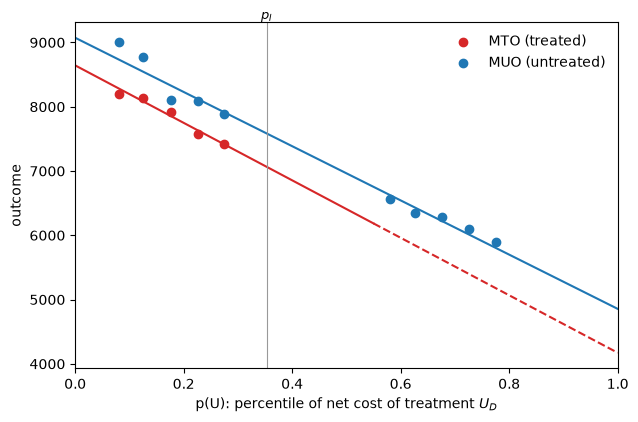

In [5]:
# Fit WITH strata="stratum": each stratum contributes its own propensity
# point, restoring linear MTO identification (and giving MUO/MTO more points
# than coefficients, so an overidentification/linearity check runs too).
result_strata = mteo.fit(df, outcome="y", treatment="d", instrument="z",
                          strata="stratum", extrapolation="linear",
                          bootstrap_reps=200, seed=1)
result_strata.plot()


In [6]:
for k in ("late", "att", "atu", "ate"):
    e = result_strata.estimands[k]
    shown = e.value if e.status in ("point", "extrapolated") else e.bounds
    print(f"{k:4s} status={e.status:14s} value/bounds={shown}")


late status=point          value/bounds=-479.75032409615415
att  status=point          value/bounds=-479.75032409615415
atu  status=extrapolated   value/bounds=-556.4414084643959
ate  status=extrapolated   value/bounds=-556.4414084643959


In [7]:
# "Should we expand treatment?" -- predict the LATE for the next slice of
# units just beyond the current take-up margin (p_hi + 0.1), the units who
# would only take up under stronger encouragement than today's.
p_hi = result_strata.groups.p_i
expansion = result_strata.predict_late(p_hi, min(p_hi + 0.1, 1.0))
print(f"expansion margin: ({p_hi:.3f}, {min(p_hi + 0.1, 1.0):.3f}]")
print(f"status: {expansion.status}")
print(f"predicted LATE for the expansion margin: {expansion.value:.2f}")


expansion margin: (0.353, 0.453]
status: point
predicted LATE for the expansion margin: -531.81


In [8]:
# Pooling caveat: strata pooling assumes MUO/MTO are common across strata in
# p(U) (BMW additive separability). score_on_u correlates the take-up
# score with U_D, breaking within-stratum uniformity -- the overidentification
# statistic should inflate as the maintained linear shape is violated.
dgp_broken = OneSidedDGP(score_on_u=0.5)
df_broken = dgp_broken.sample(50_000, seed=2)
result_broken = mteo.fit(df_broken, outcome="y", treatment="d", instrument="z",
                          strata="stratum", extrapolation="linear", bootstrap_reps=0)

print(f"overid stat, clean pooling   (score_on_u=0.0): {result_strata.tests.overid.stat:.4g}")
print(f"overid stat, broken pooling  (score_on_u=0.5): {result_broken.tests.overid.stat:.4g}")


overid stat, clean pooling   (score_on_u=0.0): 5.848e+08
overid stat, broken pooling  (score_on_u=0.5): 1.426e+10


src/mteo/groups.py:142: WeakInstrumentWarning: take-up gap p_I - p_C = 0.0020 is thin; complier quantities and any extrapolation will be fragile
  per[level] = summarize_groups(y[m], d[m], z[m], w[m], min_take_up_gap=min_take_up_gap)


## What strata added

Arm-level take-up alone (no strata) point-identifies the group shares, LATE,
and the untreated-outcome selection test under LATE assumptions only -- no
functional-form assumption required, and it is exactly what a pooled
one-sided RCT gives you. But it collapses every complier-treated observation
into a single propensity point, so a linear MTO is not identified: any
attempt to extrapolate raises `IdentificationError` naming strata as the
remedy, rather than silently reporting a made-up curve.

Adding `strata="stratum"` (a predicted-take-up covariate uncorrelated with
`U_D` in this DGP) supplies one extra propensity point per stratum on both
the treated and untreated side. That restores full linear MTO identification,
unlocks ATT/ATU/ATE and `predict_late` at margins beyond the observed
complier range, and -- because there are now more propensity points than
curve coefficients -- adds an overidentification test of the maintained
linear shape. The `score_on_u=0.5` variant shows what happens when the
covariate-variation assumption is violated instead of satisfied: the same
pooling machinery runs without error, but the overidentification statistic
inflates, which is the diagnostic (not a crash) `mteo` gives you when strata
pooling is quietly wrong.